<a href="https://colab.research.google.com/github/Asfia-Arpi/ML-Projects/blob/main/Customer_Review_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installing libraries and load data

In [5]:
%pip install -U datasets huggingface_hub scikit-learn pandas numpy matplotlib seaborn joblib streamlit

  Using cached datasets-5.1.0-py3-none-any.whl.metadata (24 kB)
  Using cached huggingface_hub-2.2.0-py3-none-any.whl.metadata (16 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 851.1 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.6 MB/s eta 0:00:00
Using cached datasets-5.1.0-py3-none-any.whl (604 kB)
Using cached huggingface_hub-2.2.0-py3-none-any.whl (839 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 41.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 45.3 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import time

from datasets import load_dataset
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42

# Load IMDb dataset using its full repository ID
dataset = load_dataset("stanfordnlp/imdb")

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

print("Dataset loaded successfully!")
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())
print("\nTraining label distribution:")
print(train_df["label"].value_counts().sort_index())

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset loaded successfully!
Training shape: (25000, 2)
Testing shape: (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0



Training label distribution:
label
0    12500
1    12500
Name: count, dtype: int64


Data exploration & quality checks

Missing values:
text     0
label    0
dtype: int64

Duplicate reviews: 96

Label mapping:
0 = Negative
1 = Positive


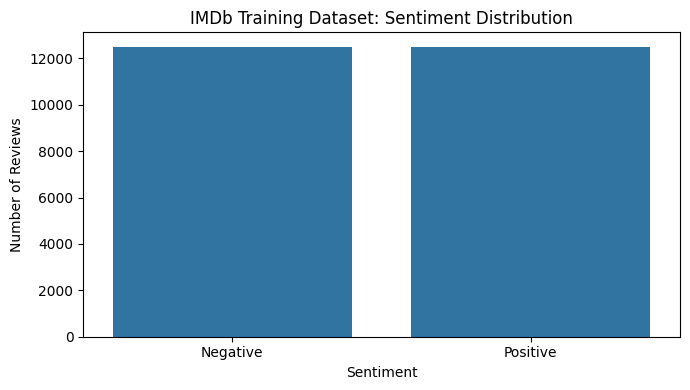

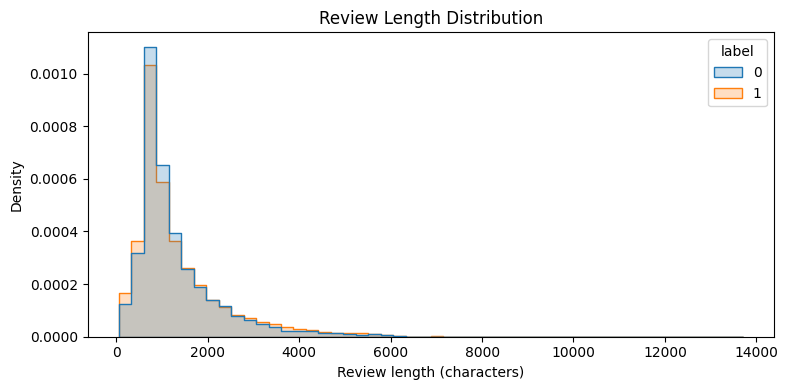


Sample review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and 

In [2]:
print("Missing values:")
print(train_df[["text", "label"]].isnull().sum())

print("\nDuplicate reviews:", train_df["text"].duplicated().sum())

print("\nLabel mapping:")
print("0 = Negative")
print("1 = Positive")

train_df["review_length"] = train_df["text"].str.len()

plt.figure(figsize=(7, 4))
sns.countplot(data=train_df, x="label")
plt.xticks([0, 1], ["Negative", "Positive"])
plt.title("IMDb Training Dataset: Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(
    data=train_df,
    x="review_length",
    hue="label",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Review Length Distribution")
plt.xlabel("Review length (characters)")
plt.tight_layout()
plt.show()

print("\nSample review:")
print(train_df["text"].iloc[0])
print("Label:", train_df["label"].iloc[0])

Prepare training and test data

In [3]:
X_train = train_df["text"].fillna("").astype(str)
y_train = train_df["label"].astype(int)

X_test = test_df["text"].fillna("").astype(str)
y_test = test_df["label"].astype(int)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training labels:", sorted(y_train.unique()))
print("Testing labels:", sorted(y_test.unique()))

Training samples: 25000
Testing samples: 25000
Training labels: [np.int64(0), np.int64(1)]
Testing labels: [np.int64(0), np.int64(1)]


Build NLP pipelines & tune models

In [4]:
models = {
    "Naive Bayes": (
        MultinomialNB(),
        {
            "clf__alpha": [0.1, 0.5, 1.0]
        }
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        {
            "clf__C": [0.1, 1.0, 10.0]
        }
    ),
    "Linear SVM": (
        LinearSVC(random_state=RANDOM_STATE),
        {
            "clf__C": [0.1, 1.0, 10.0]
        }
    )
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

best_models = {}
results = []

for name, (classifier, param_grid) in models.items():
    print(f"\n{'=' * 55}")
    print("Training:", name)

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("clf", classifier)
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1,
        error_score="raise"
    )

    start_time = time.time()
    grid.fit(X_train, y_train)
    elapsed = time.time() - start_time

    best_model = grid.best_estimator_
    best_models[name] = best_model

    # Evaluate once on the official test set
    y_pred = best_model.predict(X_test)

    result = {
        "Model": name,
        "Best CV F1": grid.best_score_,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Training Time (seconds)": round(elapsed, 2),
        "Best Parameters": str(grid.best_params_)
    }

    results.append(result)

    print("Best parameters:", grid.best_params_)
    print("Best cross-validation F1:", round(grid.best_score_, 4))
    print("Elapsed seconds:", round(elapsed, 2))

    print("\nTest classification report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nFinal model comparison:")
display(
    results_df.sort_values(
        "Best CV F1", ascending=False
    ).reset_index(drop=True)
)


Training: Naive Bayes
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best parameters: {'clf__alpha': 0.1}
Best cross-validation F1: 0.8783
Elapsed seconds: 126.86

Test classification report:
              precision    recall  f1-score   support

    Negative       0.87      0.88      0.87     12500
    Positive       0.88      0.86      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000


Training: Logistic Regression
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best parameters: {'clf__C': 10.0}
Best cross-validation F1: 0.9025
Elapsed seconds: 130.99

Test classification report:
              precision    recall  f1-score   support

    Negative       0.90      0.90      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0

,Model,Best CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Training Time (seconds),Best Parameters
0,Logistic Regression,0.902477,0.90056,0.900432,0.90072,0.900576,130.99,{'clf__C': 10.0}
1,Linear SVM,0.900303,0.89344,0.894450,0.89216,0.893303,132.95,{'clf__C': 1.0}
2,Naive Bayes,0.878280,0.87076,0.876391,0.86328,0.869786,126.86,{'clf__alpha': 0.1}


Compare models visually

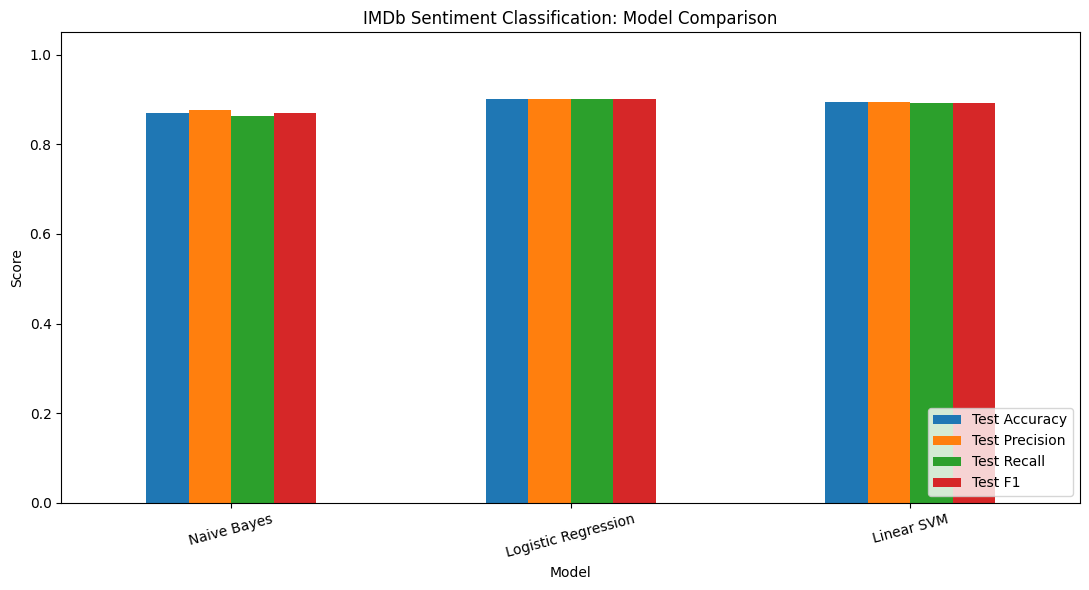

In [5]:
metrics = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]

ax = results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("IMDb Sentiment Classification: Model Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_xlabel("Model")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

Selected model: Logistic Regression

Final test metrics:
Accuracy : 0.9006
Precision: 0.9004
Recall   : 0.9007
F1-score : 0.9006


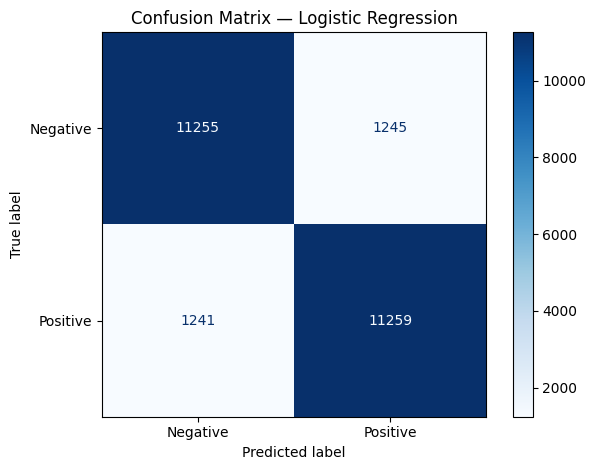

In [6]:
best_name = results_df.loc[
    results_df["Best CV F1"].idxmax(), "Model"
]

best_model = best_models[best_name]
best_predictions = best_model.predict(X_test)

print("Selected model:", best_name)
print("\nFinal test metrics:")
print("Accuracy :", round(accuracy_score(y_test, best_predictions), 4))
print("Precision:", round(precision_score(y_test, best_predictions), 4))
print("Recall   :", round(recall_score(y_test, best_predictions), 4))
print("F1-score :", round(f1_score(y_test, best_predictions), 4))

cm = confusion_matrix(
    y_test, best_predictions, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

Selected model: Logistic Regression
Test ROC-AUC: 0.9641


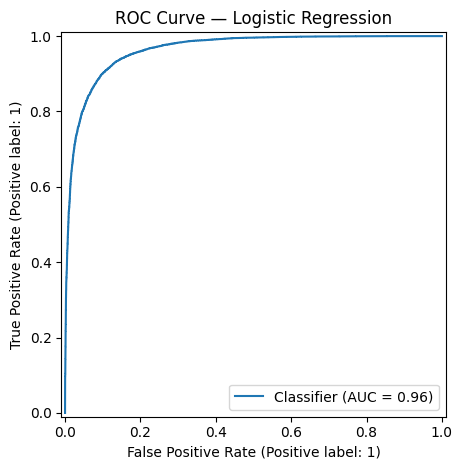

In [7]:
if hasattr(best_model, "decision_function"):
    y_scores = best_model.decision_function(X_test)
else:
    y_scores = best_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_scores)

print("Selected model:", best_name)
print("Test ROC-AUC:", round(auc, 4))

RocCurveDisplay.from_predictions(y_test, y_scores)
plt.title(f"ROC Curve — {best_name}")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# Save selected model
joblib.dump(best_model, "sentiment_model.joblib")

# Save model comparison table
results_df.sort_values(
    "Best CV F1", ascending=False
).to_csv("model_comparison.csv", index=False)

# Save selected model name and metrics
final_summary = {
    "selected_model": best_name,
    "test_accuracy": float(accuracy_score(y_test, best_predictions)),
    "test_precision": float(precision_score(y_test, best_predictions)),
    "test_recall": float(recall_score(y_test, best_predictions)),
    "test_f1": float(f1_score(y_test, best_predictions)),
    "test_roc_auc": float(auc)
}

pd.Series(final_summary).to_json(
    "final_metrics.json", indent=4
)

print("Saved files:")
for filename in [
    "sentiment_model.joblib",
    "model_comparison.csv",
    "final_metrics.json",
    "model_comparison.png",
    "confusion_matrix.png",
    "roc_curve.png"
]:
    print("✓", filename)

Saved files:
✓ sentiment_model.joblib
✓ model_comparison.csv
✓ final_metrics.json
✓ model_comparison.png
✓ confusion_matrix.png
✓ roc_curve.png


Test a custom review

In [9]:
sample_reviews = [
    "This movie was wonderful, emotional, and beautifully acted.",
    "The movie was boring, poorly written, and a complete waste of time."
]

predictions = best_model.predict(sample_reviews)

for review, prediction in zip(sample_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("\nReview:", review)
    print("Predicted sentiment:", sentiment)


Review: This movie was wonderful, emotional, and beautifully acted.
Predicted sentiment: Positive

Review: The movie was boring, poorly written, and a complete waste of time.
Predicted sentiment: Negative


In [10]:
app_code = r'''
import streamlit as st
import joblib

@st.cache_resource
def load_model():
    return joblib.load("sentiment_model.joblib")

model = load_model()

st.set_page_config(
    page_title="IMDb Sentiment Analyzer",
    page_icon="🎬",
    layout="centered"
)

st.title("🎬 Movie Review Sentiment Analyzer")
st.write(
    "Enter an English movie review to predict "
    "whether its sentiment is positive or negative."
)

review = st.text_area(
    "Enter your movie review",
    height=180,
    placeholder="Type your review here..."
)

if st.button("Analyze Sentiment", type="primary"):
    if not review.strip():
        st.warning("Please enter a review first.")
    else:
        prediction = int(model.predict([review])[0])

        if prediction == 1:
            st.success("Predicted sentiment: Positive 😊")
        else:
            st.error("Predicted sentiment: Negative ☹️")

st.caption(
    "Educational NLP project trained on IMDb movie reviews. "
    "Predictions may be incorrect."
)
'''

requirements = """datasets
huggingface_hub
scikit-learn
pandas
numpy
matplotlib
seaborn
joblib
streamlit
"""

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

print("Created app.py and requirements.txt")

Created app.py and requirements.txt


In [11]:
from google.colab import files

files.download("app.py")
files.download("requirements.txt")
files.download("sentiment_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>